In [1]:
import scanpy as sc
import numpy as np

# Load RNA data
adata = sc.read_h5ad("velten_rna.h5ad")

# Load outputs
V = np.load("V_pred.npy")   # cells x genes
A = np.load("A.npy")        # genes x TFs

print("adata:", adata.shape)
print("V:", V.shape)
print("A:", A.shape)

adata: (1035, 12553)
V: (1035, 12553)
A: (12553, 336)


In [2]:
print("Mean |V|:", np.mean(np.abs(V)))
print("Max |V|:", np.max(np.abs(V)))

Mean |V|: 0.0018971869
Max |V|: 0.68847793


In [3]:
adata.layers["velocity"] = V

In [4]:
adata

AnnData object with n_obs × n_vars = 1035 × 12553
    obs: 'plate', 'well', 'facs_fsc.area', 'facs_fsc_height', 'facs_ssc.area', 'facs_ssc_height', 'facs_cd45ra', 'facs_cd135', 'facs_cd90', 'facs_cd49f', 'facs_lin', 'facs_cd34', 'facs_cd38', 'facs_cd10', 'culture_key', 'culture_cells_in_colony', 'culture_mk_cd41+', 'culture_ery_cd235+', 'culture_total_number_of_my_cd33+', 'facs_pseudotime', 'fate_stemness', 'n_genes', 'dpt_pseudotime'
    var: 'n_cells'
    obsm: 'X_diffmap', 'X_pca', 'X_umap'
    layers: 'counts', 'velocity'

In [5]:
adata.uns.pop("diffmap_evals", None)
adata.obsm.pop("X_diffmap", None)

array([[-0.02990121,  0.00325548,  0.00092629, ...,  0.01397544,
         0.03854025,  0.02658261],
       [-0.03216717,  0.00368505,  0.05786094, ...,  0.00739186,
        -0.04719813, -0.00721231],
       [-0.03177452,  0.00314542,  0.03635098, ..., -0.00066579,
        -0.02659807, -0.01218821],
       ...,
       [-0.03094353,  0.00374048, -0.05663225, ...,  0.01608328,
        -0.00025809, -0.02010937],
       [-0.03103779,  0.00334401,  0.00802352, ...,  0.0025664 ,
         0.02612641,  0.05090882],
       [-0.03123204,  0.00287294,  0.00539664, ...,  0.02804749,
         0.01329352, -0.0381385 ]], shape=(1035, 15), dtype=float32)

In [6]:
# force clean neighborhood graph
sc.pp.neighbors(
    adata,
    use_rep="X",   # or "X_pca" if you prefer
    n_neighbors=15,
    key_added="neighbors_clean"
)

sc.tl.umap(adata, neighbors_key="neighbors_clean")

/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [9]:
# approximate projection using linear regression idea
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(adata.X, V)          # gene space → velocity
V_umap = model.predict(adata.X)

adata.obsm["velocity_umap"] = V_umap

KeyboardInterrupt: 

In [ ]:
sc.pl.embedding(
    adata,
    basis="umap",
    show=False
)

In [ ]:
import matplotlib.pyplot as plt

X = adata.obsm["X_umap"]
V = adata.obsm["velocity_umap"]

plt.figure(figsize=(6,6))
plt.scatter(X[:,0], X[:,1], s=5, alpha=0.5)

# downsample for clarity
idx = np.random.choice(len(X), 200, replace=False)

plt.quiver(
    X[idx,0], X[idx,1],
    V[idx,0], V[idx,1],
    angles="xy", scale_units="xy", scale=1
)

plt.title("Learned regulatory velocity on UMAP")
plt.show()

In [11]:
import scvelo as scv
import scanpy as sc
import numpy as np

adata = sc.read_h5ad("velten_rna.h5ad")
V = np.load("V_pred.npy")
adata.layers["velocity"] = V

adata.uns.pop("diffmap_evals", None)
adata.obsm.pop("X_diffmap", None)

# scVelo needs its own neighbor graph — recompute through it
scv.pp.moments(adata, n_pcs=30, n_neighbors=30)  # builds connectivities scvelo expects

# Build the velocity graph in gene space (no 'spliced' needed if you set xkey)
scv.tl.velocity_graph(adata, vkey="velocity", xkey="Ms")  # Ms is created by moments()

# Project into UMAP
scv.tl.velocity_embedding(adata, basis="umap", vkey="velocity")

scv.pl.velocity_embedding_stream(
    adata, basis="umap", vkey="velocity",
    color="your_cluster_key",  # or remove color arg
    title="Regulatory velocity"
)

computing neighbors
    finished (0:00:00) --> added 
    'distances' and 'connectivities', weighted adjacency matrices (adata.obsp)


/tmp/ipykernel_2605/1978152498.py:13: DeprecationWarning: Automatic neighbor calculation is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors first with Scanpy.
  scv.pp.moments(adata, n_pcs=30, n_neighbors=30)  # builds connectivities scvelo expects
/home/sc5625/.local/share/mamba/envs/atac-process/lib/python3.14/site-packages/scvelo/preprocessing/moments.py:71: DeprecationWarning: `neighbors` is deprecated since scvelo==0.4.0 and will be removed in a future version of scVelo. Please compute neighbors with Scanpy.
  neighbors(


KeyError: 'spliced'

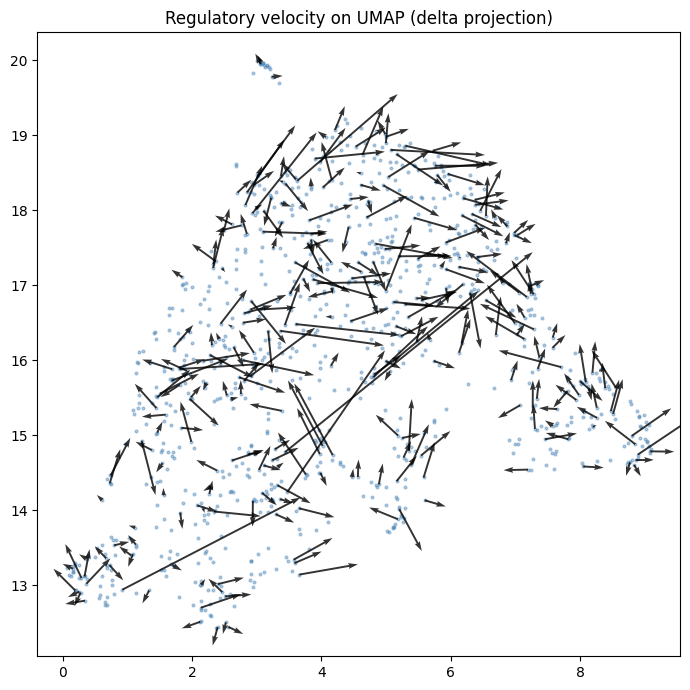

In [12]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
from umap import UMAP

adata = sc.read_h5ad("velten_rna.h5ad")
V = np.load("V_pred.npy")

X = adata.X if not hasattr(adata.X, "toarray") else adata.X.toarray()

# Fit UMAP on expression
reducer = UMAP(n_neighbors=15, random_state=42)
X_umap = reducer.fit_transform(X)

# Project perturbed cells: X + epsilon*V → UMAP, measure displacement
epsilon = 1.0
X_perturbed = X + epsilon * V
X_perturbed_umap = reducer.transform(X_perturbed)

V_umap = (X_perturbed_umap - X_umap) / epsilon  # velocity in UMAP space

# Plot
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X_umap[:, 0], X_umap[:, 1], s=4, alpha=0.4, c="steelblue")

idx = np.random.choice(len(X_umap), 300, replace=False)
ax.quiver(
    X_umap[idx, 0], X_umap[idx, 1],
    V_umap[idx, 0], V_umap[idx, 1],
    alpha=0.8, scale=5, width=0.003
)
ax.set_title("Regulatory velocity on UMAP (delta projection)")
plt.tight_layout()
plt.show()